# 2019 L-band cross-correlation with multiscale PCA (mPCA)

This recipe repeats the [2019 L-band cross-correlation](2019_Lband.ipynb) (MeerKLASS 2019 L-band × WiggleZ) with
the **multiscale PCA** (mPCA) foreground cleaning of
[Carucci et al. 2025, A&A 703, A222](https://doi.org/10.1051/0004-6361/202453461), available as
`meer21cm.mpca.mpca_clean`, and compares it with PCA.

PCA finds one set of foreground modes along frequency for all angular scales. mPCA first splits each channel map
into a **coarse** (large angular scales) and a **fine** (small angular scales) part with a starlet wavelet
transform, and runs a separate PCA on each, removing $N_{\rm L}$ modes from the coarse part and $N_{\rm S}$ from
the fine part:

$$\mathbf{d}_{\rm clean} = (I - A_{\rm L}A_{\rm L}^T)\,\mathbf{d}_{\rm coarse} + (I - A_{\rm S}A_{\rm S}^T)\,\mathbf{d}_{\rm fine}.$$

Large scales carry most of the foreground power and of the instrumental systematics; small scales are closer to
thermal noise. Cleaning each with its own number of modes removes less HI signal than PCA for the same
foreground removal.

Data: the MeerKLASS 2019 maps from [meerklass.org](https://meerklass.org/data.html), and the WiggleZ 11h-region
galaxies and selection function gridded on the 2019 map pixels and channels, as used in the paper.

**No transfer function.** All amplitudes below are therefore lower limits, for PCA and
mPCA alike. Errors are the Gaussian ones of the 2019 L-band recipe, which underestimate the real scatter.

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal.windows import tukey
from meer21cm import PowerSpectrum
from meer21cm.util import pca_clean, mean_center_signal, radec_to_indx
from meer21cm.mpca import mpca_clean, starlet_split
from meer21cm.telescope import dish_beam_sigma
from meer21cm.plot import plot_map

plt.rcParams.update({'font.size': 14})

In [2]:
file_dir = './'
pickle_file = file_dir + 'MK_2019_maps.pkl'
ng_file = file_dir + 'data_from_ilifu/WiggleZ_n_g.npy'          # WiggleZ galaxies per map voxel
sel_file = file_dir + 'data_from_ilifu/WiggleZ_selection.npy'   # WiggleZ selection: expected galaxies per voxel

ps = PowerSpectrum(
    pickle_file=pickle_file,
    beam_model='gaussian',
    beam_type='isotropic',
    band='L',
    survey='meerklass_2019',
)
ps.nu_min = 970e6  # keep all 250 channels (the survey preset drops the first one)
ps.nu_max = 1024e6
ps.read_from_pickle()
ps.sigma_beam_ch = dish_beam_sigma(13.5, ps.nu)
nz = ps.nu.size
print(ps.data.shape)

filtering map los
(133, 41, 250)


We use the paper's Conservative Footprint (CF, stored in the pickle): a 64 × 17 pixel rectangle with high,
uniform hits.

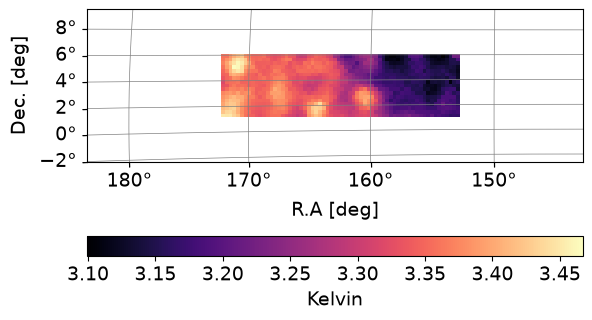

In [3]:
with open(pickle_file, 'rb') as f:
    CF = np.asarray(pickle.load(f)['CF_mask']) > 0
CF3 = np.repeat(CF[:, :, None], nz, axis=-1)
ps.data = np.nan_to_num(ps.data) * CF3
ps.counts = np.nan_to_num(ps.counts) * CF3
ps.map_has_sampling = ps.map_has_sampling * CF3
ps.weights_map_pixel = ps.weights_map_pixel * CF3
ps.ra_range = np.array([ps.ra_map[CF].min() - 0.3, ps.ra_map[CF].max() + 0.3])
ps.dec_range = np.array([ps.dec_map[CF].min() - 0.3, ps.dec_map[CF].max() + 0.3])
MKmap_orig = ps.data.copy()
ones_cf = CF3.astype(float)
sx, sy = np.where(CF)
box = (slice(sx.min(), sx.max() + 1), slice(sy.min(), sy.max() + 1))
plot_map(ps.data, ps.wproj, W=CF3, cbar_label='Kelvin')

## The two scales

`starlet_split` returns the scales of the maps along a new last axis: fine first, coarse last; they add up to
the input. With one detail scale (`J=1`, as in the paper), the coarse scale is each channel map smoothed with a
B3-spline kernel of ~5 pixels, and the fine scale is the rest. `footprint` marks the pixels with data.

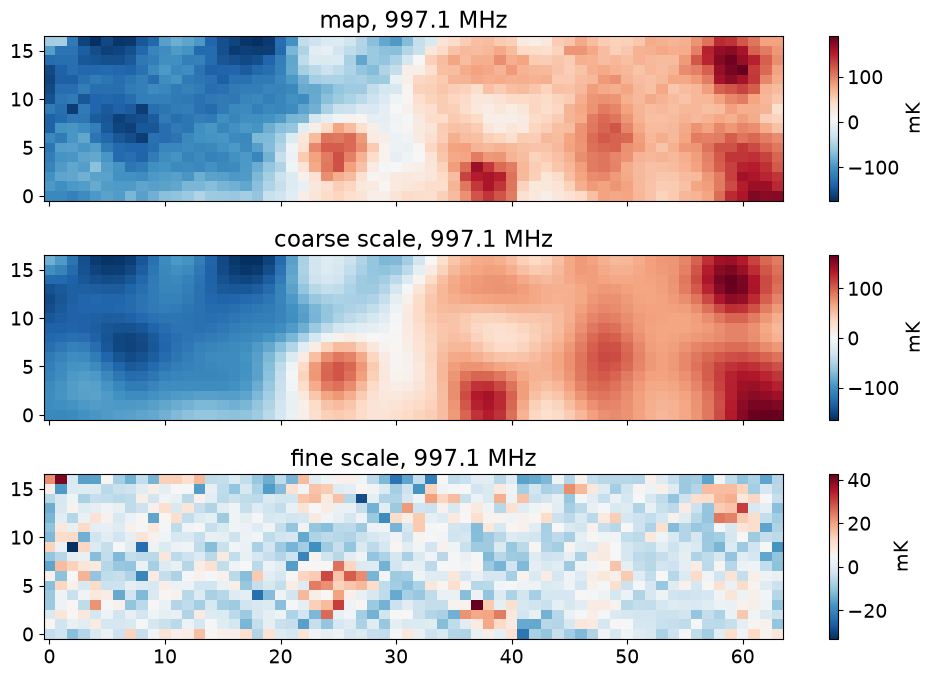

In [4]:
map_mc = mean_center_signal(MKmap_orig, ones_cf) * CF3
scales = starlet_split(map_mc, footprint=CF)
fine, coarse = scales[..., 0], scales[..., 1]

ch = nz // 2
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, m, t in zip(axes, [map_mc, coarse, fine], ['map', 'coarse scale', 'fine scale']):
    im = ax.imshow(1e3 * m[box][:, :, ch].T, origin='lower', cmap='RdBu_r', aspect='auto')
    ax.set_title(f'{t}, {ps.nu[ch] / 1e6:.1f} MHz')
    plt.colorbar(im, ax=ax, label='mK')
plt.tight_layout()

Eigenvalues of the frequency-frequency covariance of the full maps (what PCA decomposes) and of each scale
(what mPCA decomposes). The coarse scale holds most of the foreground power and needs few modes; the fine scale
has a flatter spectrum, so more of its modes are noise-like.

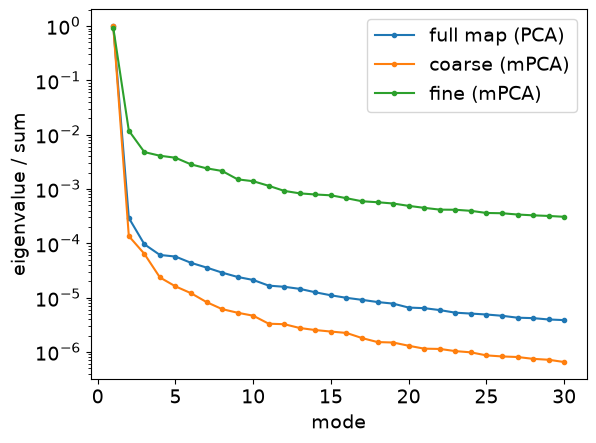

In [5]:
eig = {}
for name, m in [('full map (PCA)', map_mc), ('coarse (mPCA)', coarse), ('fine (mPCA)', fine)]:
    _, _, eig[name], _ = pca_clean(m, 1, weights=ones_cf, return_analysis=True)
plt.figure()
for name, e in eig.items():
    plt.semilogy(np.arange(1, 31), e[:30] / e.sum(), 'o-', ms=3, label=name)
plt.xlabel('mode')
plt.ylabel('eigenvalue / sum')
plt.legend()

## Cleaning

PCA with $N_{\rm fg} = 4$ and mPCA with $(N_{\rm L}, N_{\rm S}) = (4, 8)$, the paper's choices, mean-centred
inside the CF. `weights=ones_cf` (PCA) and `footprint=CF` (mPCA) keep the empty pixels outside the CF out of the
means and covariances.

Two weighted PCAs, which differ only in the weights:

- **PCAw**: each pixel weighted by its hits averaged along the line of sight, the same weight in every channel,
  as in the paper;
- **PCAw2**: the hits of each pixel in each channel, i.e. weights that change with frequency (as in the 2019
  L-band recipe). Multiplying the maps by frequency-dependent weights mixes frequency modes before the PCA.

In both, as in the paper, the mean of the weighted maps is removed before computing the covariance, which we
build and pass to `pca_clean`. (`pca_clean(..., weights=...)` instead weights the mean-centred maps, a further
difference we avoid here.)

hits per channel / line-of-sight average: rms 0.079, range 0.11 - 1.67


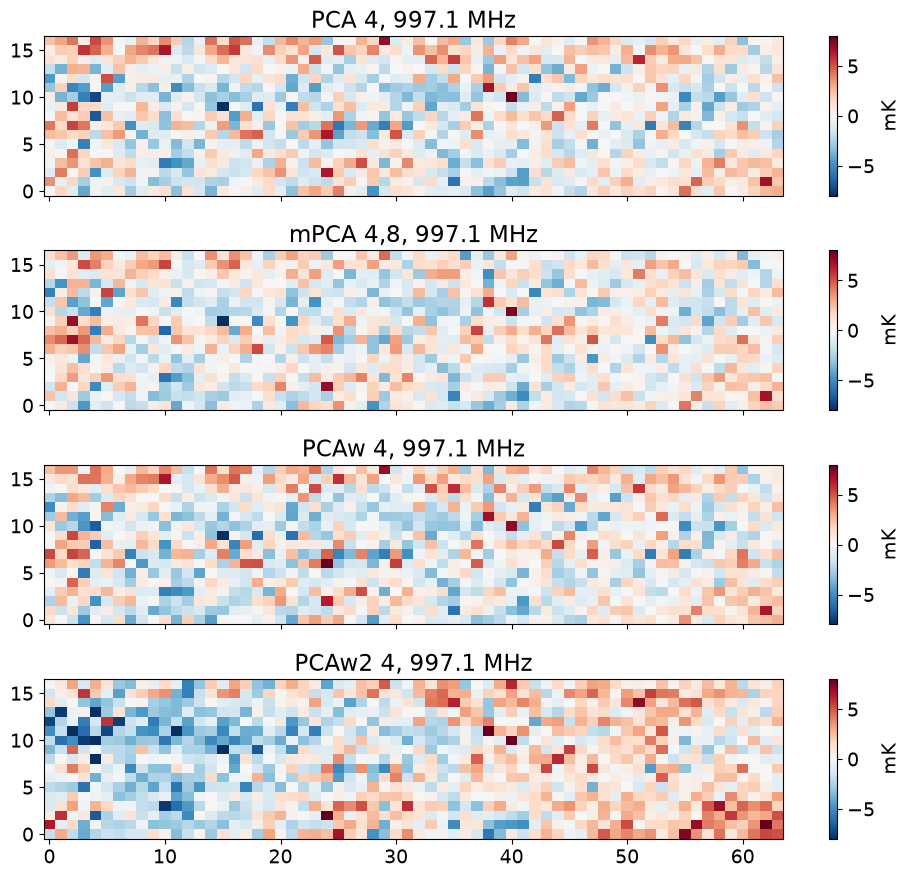

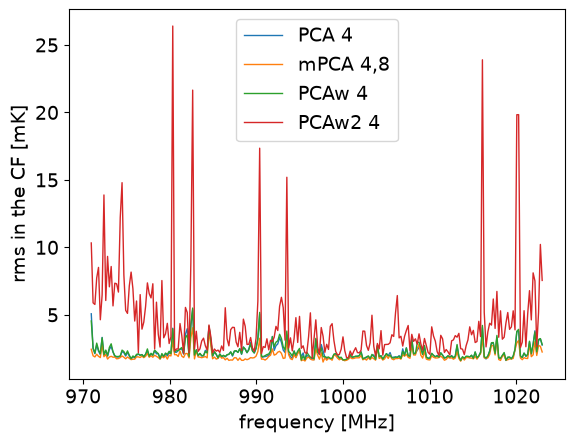

In [6]:
N_fg = 4
N_L, N_S = 4, 8
hits = ps.counts * CF3                                                      # hits per pixel and channel
w_los = np.repeat(hits.mean(axis=-1, keepdims=True), nz, axis=-1)          # averaged along the line of sight

def weighted_cov(w):
    """nu-nu covariance of the weighted maps, with the mean of the weighted maps removed (as in the paper)."""
    y = (w * MKmap_orig)[CF]
    y = y - y.mean(axis=0)
    return y.T @ y

cleaned = {
    f'PCA {N_fg}': pca_clean(MKmap_orig, N_fg, weights=ones_cf, mean_center=True) * CF3,
    f'mPCA {N_L},{N_S}': mpca_clean(MKmap_orig, N_L, N_S, mean_center=True, footprint=CF),
    f'PCAw {N_fg}': pca_clean(MKmap_orig, N_fg, weights=ones_cf, mean_center=True,
                              covariance=weighted_cov(w_los)) * CF3,
    f'PCAw2 {N_fg}': pca_clean(MKmap_orig, N_fg, weights=ones_cf, mean_center=True,
                               covariance=weighted_cov(hits)) * CF3,
}
r = hits[CF] / w_los[CF]
print(f'hits per channel / line-of-sight average: rms {r.std():.3f}, range {r.min():.2f} - {r.max():.2f}')
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, (name, m) in zip(axes, cleaned.items()):
    im = ax.imshow(1e3 * m[box][:, :, ch].T, origin='lower', cmap='RdBu_r', aspect='auto', vmin=-8, vmax=8)
    ax.set_title(f'{name}, {ps.nu[ch] / 1e6:.1f} MHz')
    plt.colorbar(im, ax=ax, label='mK')
plt.tight_layout()

plt.figure()
for name, m in cleaned.items():
    plt.plot(ps.nu / 1e6, 1e3 * np.sqrt((m[CF] ** 2).mean(axis=0)), lw=1, label=name)
plt.xlabel('frequency [MHz]')
plt.ylabel('rms in the CF [mK]')
plt.legend()

## Galaxies, randoms and gridding

The galaxy positions are known to a map voxel (0.3° × 0.21 MHz): each galaxy is placed at random inside its
voxel. The galaxy field is $F = D - \alpha R$ with randoms drawn from the selection function, 50 per galaxy
(meer21cm uses the painted randoms as the galaxy window, which must not be noise-dominated), and FKP weights
$w = 1/(1 + \bar n P_0)$ with $P_0 = 1000\,h^{-3}{\rm Mpc}^3$. A Tukey ($\alpha = 0.5$) taper across the sky
multiplies the HI, galaxy and random weights. Gridding as in the 2019 L-band recipe, with radial down-resolution 2.

In [7]:
pix_deg = np.abs(ps.wproj.wcs.cdelt[0])
dnu = np.abs(np.diff(ps.nu).mean())
nu_edges = np.concatenate([[ps.nu[0] - dnu / 2], (ps.nu[1:] + ps.nu[:-1]) / 2, [ps.nu[-1] + dnu / 2]])

def points_in_voxels(n_per_voxel, seed):
    """RA, Dec, z of n_per_voxel[i, j, k] points placed uniformly inside each map voxel."""
    rng = np.random.default_rng(seed)
    ii, jj, kk = np.nonzero(n_per_voxel)
    ii, jj, kk = [np.repeat(a, n_per_voxel[ii, jj, kk].astype(int)) for a in (ii, jj, kk)]
    dec = ps.dec_map[ii, jj] + rng.uniform(-pix_deg / 2, pix_deg / 2, ii.size)
    ra = ps.ra_map[ii, jj] + rng.uniform(-pix_deg / 2, pix_deg / 2, ii.size) / np.cos(np.deg2rad(ps.dec_map[ii, jj]))
    z = 1420.405751e6 / (ps.nu[kk] + rng.uniform(-dnu / 2, dnu / 2, kk.size)) - 1
    return ra, dec, z

def in_footprint(ra, dec, z):
    """Objects in a CF pixel and in the band, with their map pixel and channel."""
    ix, iy = radec_to_indx(ra, dec, ps.wproj)
    ich = np.digitize(1420.405751e6 / (1 + z), nu_edges) - 1
    ok = (ix >= 0) & (ix < CF.shape[0]) & (iy >= 0) & (iy < CF.shape[1]) & (ich >= 0) & (ich < nz)
    inside = np.zeros(ra.size, dtype=bool)
    inside[ok] = CF[ix[ok], iy[ok]]
    return inside, ix[inside], iy[inside], ich[inside]

n_g = np.load(ng_file)[:, :, :nz] * CF3
selection = np.load(sel_file)[:, :, :nz] * CF3
selection *= n_g.sum() / selection.sum()                      # expected galaxies per voxel
v_vox = ps.pix_resol_in_mpc**2 * ps.los_resol_in_mpc
P0 = 1000.0 / ps.h**3
nbar = selection / v_vox
T2 = np.zeros(CF.shape)
T2[box] = np.outer(tukey(box[0].stop - box[0].start, 0.5), tukey(box[1].stop - box[1].start, 0.5))
ps.weights_map_pixel = ps.weights_map_pixel * T2[:, :, None]
print(int(n_g.sum()), 'galaxies in the CF')

def galaxy_field(seed, oversample=50):
    """Grid F = D - alpha R for one placement of the galaxies and one draw of the randoms."""
    ra, dec, z = points_in_voxels(n_g, seed=seed)
    sel, gx, gy, gch = in_footprint(ra, dec, z)
    ps._ra_gal, ps._dec_gal, ps._z_gal = ra[sel], dec[sel], z[sel]
    n_r = np.random.default_rng(10_000 + seed).poisson(oversample * selection)
    ra_r, dec_r, z_r = points_in_voxels(n_r, seed=20_000 + seed)
    rs, rx, ry, rch = in_footprint(ra_r, dec_r, z_r)
    w_gal = T2[gx, gy] / (1 + nbar[gx, gy, gch] * P0)
    w_rand = T2[rx, ry] / (1 + nbar[rx, ry, rch] * P0)
    ps._fkp_random_key = None   # new randoms: do not reuse the cached paint of the previous ones
    ps.grid_gal_to_field(weights=w_gal, construct_fkp=True,
                         random_radecz=(ra_r[rs], dec_r[rs], z_r[rs]), random_weights=w_rand)

ps.downres_factor_transverse = 1.5
ps.downres_factor_radial = 2.0
ps.box_buffkick = [20, 20, 0]
ps.num_particle_per_pixel = 1
ps.grid_scheme = 'nnb'
ps.get_enclosing_box()
galaxy_field(seed=0)

def grid_hi(hi_map):
    ps.data = hi_map
    hi_map_rg, _, _ = ps.grid_data_to_field()
    return hi_map_rg

def set_fields(hi_map_rg):
    taper = ps.taper_func(ps.box_ndim[2])[None, None, :]
    ps.field_1 = hi_map_rg
    ps.weights_grid_1 = ps.counts_in_box.astype('float') * taper
    ps.weights_field_1 = None
    ps.weights_grid_2 = np.ones(ps.box_ndim) * taper   # field_2 and weights_field_2 come from grid_gal_to_field
    ps.mean_center_1, ps.mean_center_2 = False, False
    ps.unitless_1, ps.unitless_2 = False, False
    ps.sampling_resol = np.array([ps.pix_resol_in_mpc, ps.pix_resol_in_mpc, ps.los_resol_in_mpc])
    ps.compensate = True
    ps.include_sky_sampling = [True, False]

HI = {name: grid_hi(m) for name, m in cleaned.items()}   # the HI side does not change between realisations

2329 galaxies in the CF


## Power spectra

The paper's k-bins, and a one-parameter fit of $10^3\,\Omega_{\rm HI} b_{\rm HI} r$ to the model, with
$b_{\rm g} = \sqrt{0.83}$ and RSD $(1 + f\mu^2)^2$ as in the paper.

In [8]:
set_fields(HI[f'PCA {N_fg}'])
kbins = np.linspace(0.02, 0.3, 12) * ps.h
k_sel = np.ones_like(ps.k_mode)
k_sel[0], k_sel[:, 0, :], k_sel[:, :, 0] = 0.0, 0.0, 0.0  # drop the zero planes
ps.k1dbins = kbins
ps.mean_amp_1 = 'average_hi_temp'
ps.tracer_bias_1, ps.tracer_bias_2, ps.cross_coeff = 1.0, 1.0, 1.0
ps.omega_hi = 1e-3
template, _, _ = ps.get_1d_power(ps.cross_power_tracer_model, k1dweights=k_sel)
template = np.sqrt(0.83) * template

def measure(name):
    set_fields(HI[name])
    p_c, keff, nmodes = ps.get_1d_power(ps.cross_power_3d, k1dweights=k_sel)
    p_hi, _, _ = ps.get_1d_power(ps.auto_power_3d_1, k1dweights=k_sel)
    p_gg, _, _ = ps.get_1d_power(ps.auto_power_3d_2, k1dweights=k_sel)
    sigma = np.sqrt((p_c**2 + p_hi * p_gg) / 2) / np.sqrt(nmodes)  # Gaussian error
    good = np.isfinite(p_c) & (sigma > 0)
    w = 1 / sigma[good] ** 2
    F = np.sum(template[good] ** 2 * w)
    A = np.sum(p_c[good] * template[good] * w) / F
    chi2 = np.sum((p_c[good] - A * template[good]) ** 2 * w)
    return dict(k=keff, p=p_c, sigma=sigma, A=A, sigma_A=1 / np.sqrt(F), chi2_dof=chi2 / (good.sum() - 1))

Placing the galaxies inside their voxels and drawing the randoms changes the amplitudes by about ±0.1 from one
realisation to the next, as much as their Gaussian errors (the cross-power error is dominated by the galaxies'
shot noise). We therefore average over `n_real` realisations, each with a new placement and new randoms.

In [9]:
n_real = 10
runs = []
for seed in range(n_real):
    if seed > 0:
        galaxy_field(seed)
    runs.append({name: measure(name) for name in cleaned})
    print(f'realisation {seed}: ' + ' | '.join(f"{n} {runs[-1][n]['A']:.2f}" for n in cleaned))

paper = {f'PCA {N_fg}': '0.50 ± 0.16', f'mPCA {N_L},{N_S}': '0.93 ± 0.17',
         f'PCAw {N_fg}': '0.79 ± 0.17', f'PCAw2 {N_fg}': '-'}
print(f"\n{'':10s}   10^3 Omega_HI b_HI r                         paper (Table 1)")
for name in cleaned:
    A = np.array([r[name]['A'] for r in runs])
    print(f"{name:10s}   {A.mean():.2f} ± {np.mean([r[name]['sigma_A'] for r in runs]):.2f} "
          f"(scatter over realisations {A.std(ddof=1):.2f}, "
          f"chi2/dof {np.mean([r[name]['chi2_dof'] for r in runs]):.2f})    "
          f"{paper[name]}")

realisation 0: PCA 4 0.36 | mPCA 4,8 0.73 | PCAw 4 0.72 | PCAw2 4 0.41
realisation 1: PCA 4 0.48 | mPCA 4,8 0.79 | PCAw 4 0.72 | PCAw2 4 0.54
realisation 2: PCA 4 0.56 | mPCA 4,8 0.72 | PCAw 4 0.78 | PCAw2 4 0.70
realisation 3: PCA 4 0.34 | mPCA 4,8 0.82 | PCAw 4 0.78 | PCAw2 4 0.10
realisation 4: PCA 4 0.42 | mPCA 4,8 0.69 | PCAw 4 0.67 | PCAw2 4 0.35
realisation 5: PCA 4 0.39 | mPCA 4,8 0.67 | PCAw 4 0.63 | PCAw2 4 0.02
realisation 6: PCA 4 0.64 | mPCA 4,8 1.03 | PCAw 4 0.93 | PCAw2 4 0.93
realisation 7: PCA 4 0.54 | mPCA 4,8 0.99 | PCAw 4 0.92 | PCAw2 4 0.58
realisation 8: PCA 4 0.70 | mPCA 4,8 0.89 | PCAw 4 0.93 | PCAw2 4 0.76
realisation 9: PCA 4 0.61 | mPCA 4,8 0.83 | PCAw 4 0.84 | PCAw2 4 0.21

             10^3 Omega_HI b_HI r                         paper (Table 1)
PCA 4        0.51 ± 0.15 (scatter over realisations 0.13, chi2/dof 2.96)    0.50 ± 0.16
mPCA 4,8     0.82 ± 0.14 (scatter over realisations 0.12, chi2/dof 0.89)    0.93 ± 0.17
PCAw 4       0.79 ± 0.15 (scatter over 

Text(0.5, 1.0, 'weights: line-of-sight average vs per channel')

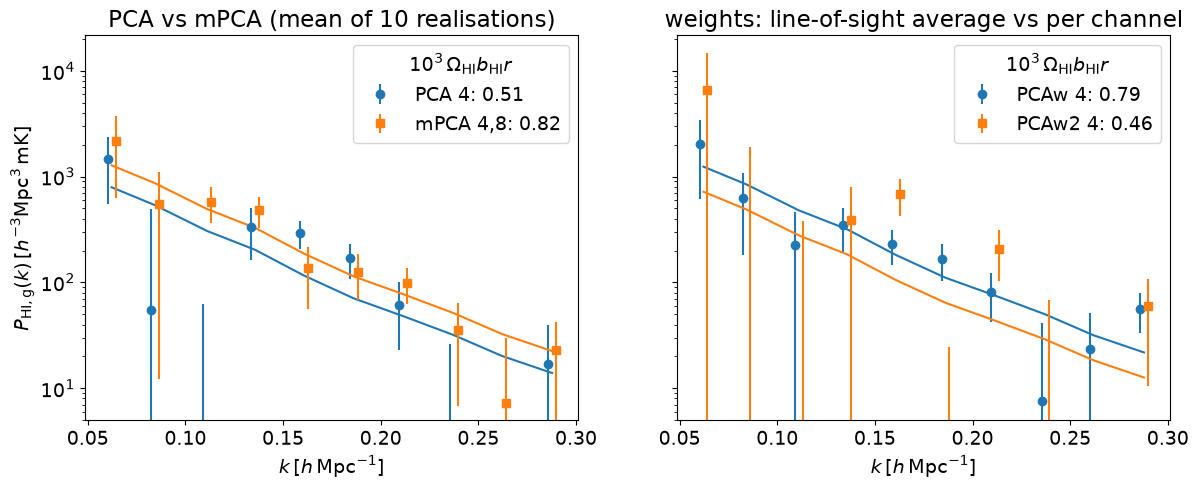

In [10]:
h = ps.h
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, pair in zip(axes, [(f'PCA {N_fg}', f'mPCA {N_L},{N_S}'), (f'PCAw {N_fg}', f'PCAw2 {N_fg}')]):
    for name, mk, dx in zip(pair, ['o', 's'], [-0.002, 0.002]):
        k = runs[0][name]['k'] / h
        p = np.mean([r[name]['p'] for r in runs], axis=0)
        s = np.mean([r[name]['sigma'] for r in runs], axis=0)
        A = np.mean([r[name]['A'] for r in runs])
        line = ax.errorbar(k + dx, p * h**3 * 1e3, yerr=s * h**3 * 1e3, ls='none', marker=mk,
                           label=f'{name}: {A:.2f}')
        ax.plot(k, A * template * h**3 * 1e3, color=line[0].get_color())
    ax.set_yscale('log')
    ax.set_xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
    ax.legend(title=r'$10^3\,\Omega_{\rm HI} b_{\rm HI} r$')
axes[0].set_ylabel(r'$P_{\rm HI,g}(k)\,[h^{-3}{\rm Mpc^3\,mK}]$')
axes[0].set_title(f'PCA vs mPCA (mean of {n_real} realisations)')
axes[1].set_title('weights: line-of-sight average vs per channel')

mPCA recovers a larger cross-correlation amplitude than PCA (0.82 against 0.51), with a much better fit to the
model ($\chi^2/{\rm dof}$ 0.9 against 3.0), as in the paper.

The weights must not depend on frequency. Weighting each pixel by its line-of-sight-averaged hits (PCAw) gives
0.79, the paper's value. With the hits of each channel instead (PCAw2), the same 4 modes leave much more
foreground in the maps: the rms of the cleaned maps is 2 to 10 times larger, with spikes in individual channels,
the error on the amplitude grows from 0.15 to 0.40, and the amplitude changes a lot between realisations
(scatter 0.30 against 0.11).

Differences from the paper's analysis:

- **power-spectrum estimation**: the paper did not use meer21cm; here the gridding to the comoving box, the
  galaxy field and window normalisation, the model and its convolution with the window, and the fit are
  meer21cm's, as in the 2019 L-band recipe;
- **realisations**: the amplitudes are averaged over placements of the galaxies inside their voxels and over
  draws of the randoms;
- **channel pairing**: galaxies and HI are paired at the same frequency; the paper's code paired HI channel $k$
  with galaxy channel $k+1$ (~0.2 MHz, under 1 Mpc/h), which lowers the amplitudes by ~0.1 on average.